In [1]:
# 1. Import libraries 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans, AgglomerativeClustering 
from scipy.cluster.hierarchy import dendrogram, linkage 

In [3]:
# 2. Read dataset 
df = pd.read_csv(r"C:\Users\Vaibhav\OneDrive\Documents\SEM7\manual\codes\ml-\sales_data_sample.csv", encoding="ISO-8859-1") 
print(df.head()) 
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
# 3. Select numerical features 
data = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']].dropna()

In [5]:
# 4. Normalize data 
scaler = StandardScaler() 
X = scaler.fit_transform(data) 

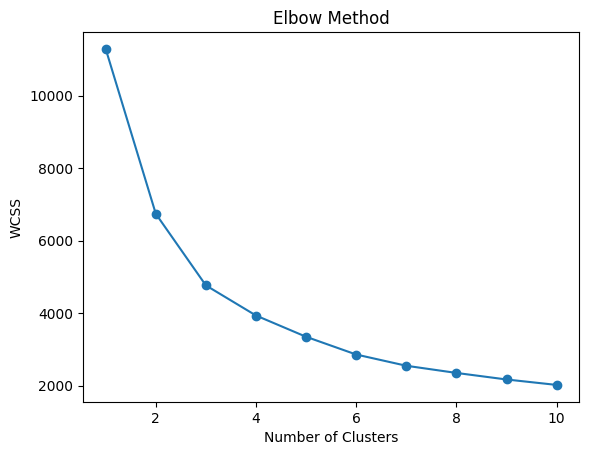

In [7]:
# 5. Determine number of clusters using Elbow Method 
wcss = [] 
for k in range(1, 11): 
    km = KMeans(n_clusters=k, random_state=42, n_init=10) 
    km.fit(X) 
    wcss.append(km.inertia_) 
plt.plot(range(1, 11), wcss, marker='o') 
plt.title("Elbow Method") 
plt.xlabel("Number of Clusters") 
plt.ylabel("WCSS") 
plt.show() 

In [8]:
# 6. Apply K-Means clustering 
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10) 
data = data.copy() 
data['KMeans_Cluster'] = kmeans.fit_predict(X) 
print("\nK-Means Cluster Counts:") 
print(data['KMeans_Cluster'].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


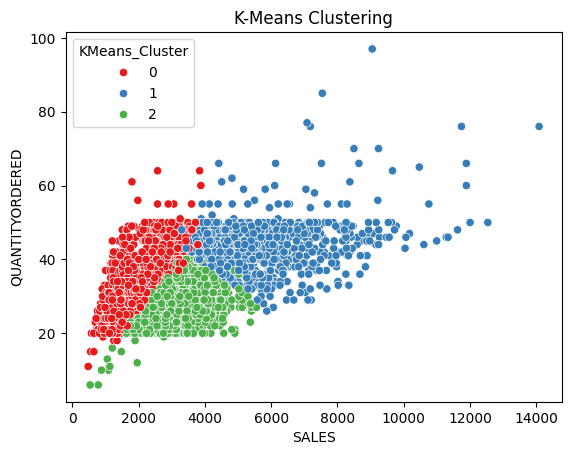

In [9]:
# 7. Visualize K-Means clusters 
sns.scatterplot( 
    x=data['SALES'], y=data['QUANTITYORDERED'], 
    hue=data['KMeans_Cluster'], palette='Set1' 
) 
plt.title("K-Means Clustering") 
plt.show()

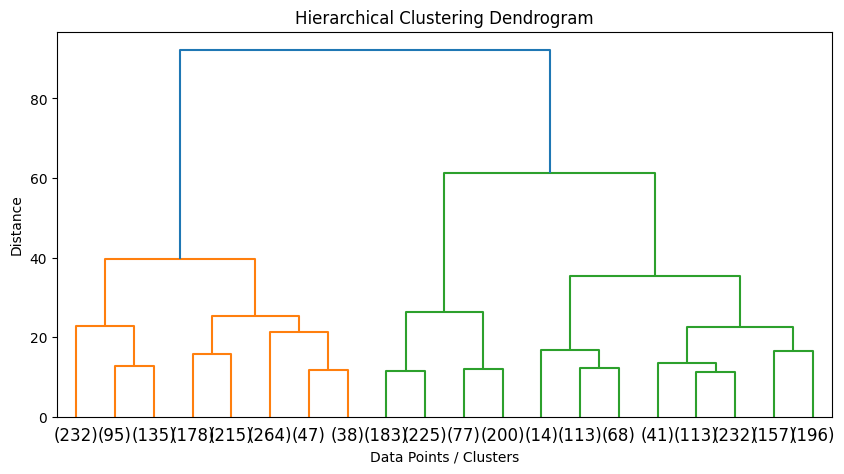

In [10]:
# 8. Hierarchical clustering 
linked = linkage(X, method='ward') 
plt.figure(figsize=(10, 5)) 
dendrogram(linked, truncate_mode='lastp', p=20) 
plt.title("Hierarchical Clustering Dendrogram") 
plt.xlabel("Data Points / Clusters") 
plt.ylabel("Distance") 
plt.show()

In [11]:
# 9. Apply Agglomerative Clustering 
hierarchical = AgglomerativeClustering(n_clusters=3) 
data['Hierarchical_Cluster'] = hierarchical.fit_predict(X) 
print("\nHierarchical Cluster Counts:") 
print(data['Hierarchical_Cluster'].value_counts()) 


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


In [12]:
# 10. Display results 
print("\nFinal Clustered Data:") 
print(data.head())


Final Clustered Data:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster  \
0               30      95.70  2871.00    95               2   
1               34      81.35  2765.90    95               2   
2               41      94.74  3884.34    95               1   
3               45      83.26  3746.70    95               1   
4               49     100.00  5205.27    95               1   

   Hierarchical_Cluster  
0                     2  
1                     2  
2                     0  
3                     0  
4                     1  
